In [33]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Datpathlibading

In [3]:
df=pd.read_csv('data/raw/Telco-Customer-Churn.csv')

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Data checking

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.describe(include='object')

C:\Users\vikra\AppData\Local\Temp\ipykernel_29280\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [11]:
df['Churn'].unique()

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

In [10]:
# Work on a copy so the original cleaned dataset is preserved.
eda = df.copy()

# Make sure the target is numeric: 1 = churn, 0 = retained.
eda["ChurnFlag"] = (
    eda["Churn"].astype(str).str.strip().str.lower()
       .map({"yes": 1, "no": 0})
)

if eda["ChurnFlag"].isna().any():
    raise ValueError("Unexpected values in the Churn column.")

# Remove the customer identifier from numerical analysis.
eda["tenure"] = pd.to_numeric(eda["tenure"], errors="coerce")
eda["MonthlyCharges"] = pd.to_numeric(
    eda["MonthlyCharges"], errors="coerce"
)
eda["TotalCharges"] = pd.to_numeric(
    eda["TotalCharges"], errors="coerce"
)

print("Retained customers:", (eda["ChurnFlag"] == 0).sum())
print("Churned customers:", (eda["ChurnFlag"] == 1).sum())
print("Overall churn rate:", round(eda["ChurnFlag"].mean() * 100, 2), "%")

Retained customers: 5174
Churned customers: 1869
Overall churn rate: 26.54 %


In [12]:
eda['ChurnFlag'].unique()

array([0, 1])

### Analyizg the Target Column

Churn
No     5174
Yes    1869
Name: count, dtype: int64


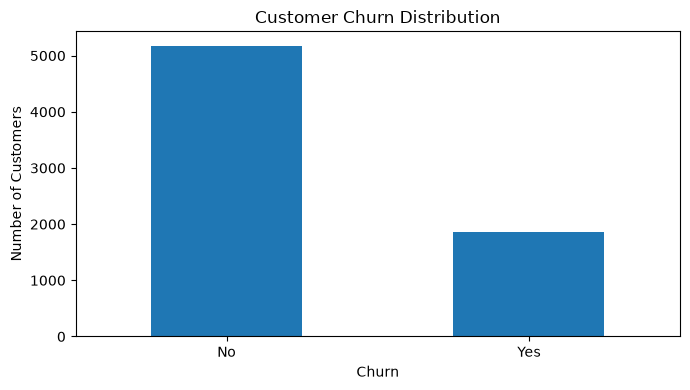

In [13]:
churn_counts = eda["Churn"].value_counts()

print(churn_counts)

ax = churn_counts.plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

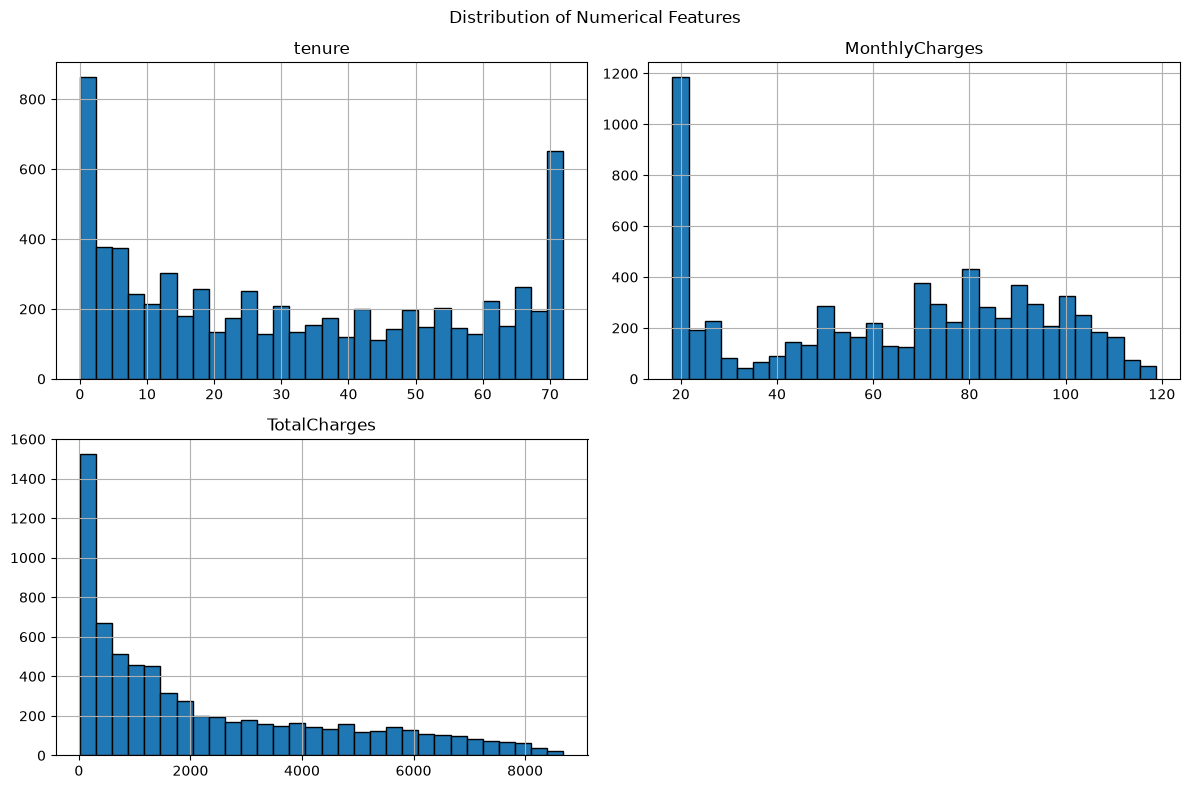

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


In [14]:
numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

eda[numeric_cols].hist(
    bins=30,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

display(eda[numeric_cols].describe().T)

In [15]:
categorical_cols = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "SeniorCitizen",
    "PaperlessBilling"
]

for col in categorical_cols:
    print(f"\nDistribution of {col}:")
    display(
        eda[col]
        .value_counts(dropna=False)
        .rename("customer_count")
        .to_frame()
    )


Distribution of Contract:


,customer_count
Contract,
Month-to-month,3875
Two year,1695
One year,1473



Distribution of InternetService:


,customer_count
InternetService,
Fiber optic,3096
DSL,2421
No,1526



Distribution of PaymentMethod:


,customer_count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522



Distribution of SeniorCitizen:


,customer_count
SeniorCitizen,
0,5901
1,1142



Distribution of PaperlessBilling:


,customer_count
PaperlessBilling,
Yes,4171
No,2872


#### Detecting the outliers

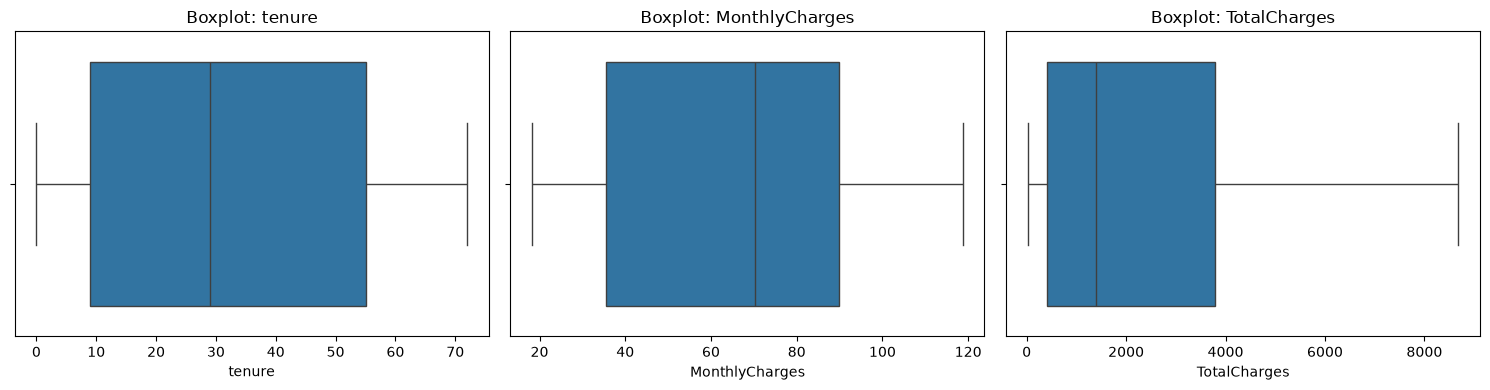

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=eda, x=col, ax=ax)
    ax.set_title(f"Boxplot: {col}")

plt.tight_layout()
plt.show()

#### Churn rate by contract type

,customers,churned,churn_rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


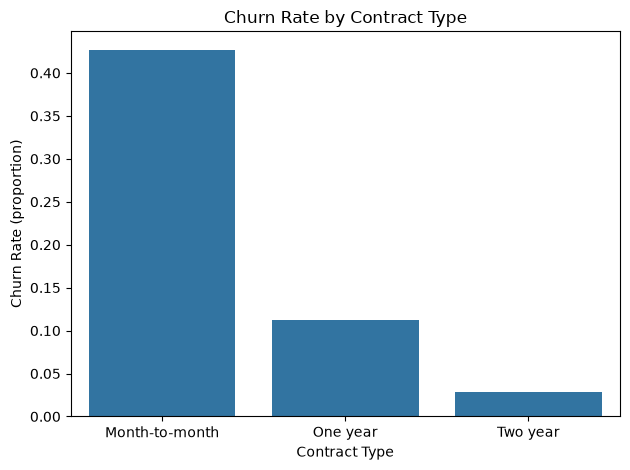

In [17]:
contract_analysis = (
    eda.groupby("Contract", dropna=False)
       .agg(
           customers=("ChurnFlag", "size"),
           churned=("ChurnFlag", "sum"),
           churn_rate=("ChurnFlag", "mean")
       )
)

contract_analysis["churn_rate"] *= 100

display(contract_analysis.round(2))

sns.barplot(
    data=eda,
    x="Contract",
    y="ChurnFlag",
    errorbar=None
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (proportion)")
plt.tight_layout()
plt.show()

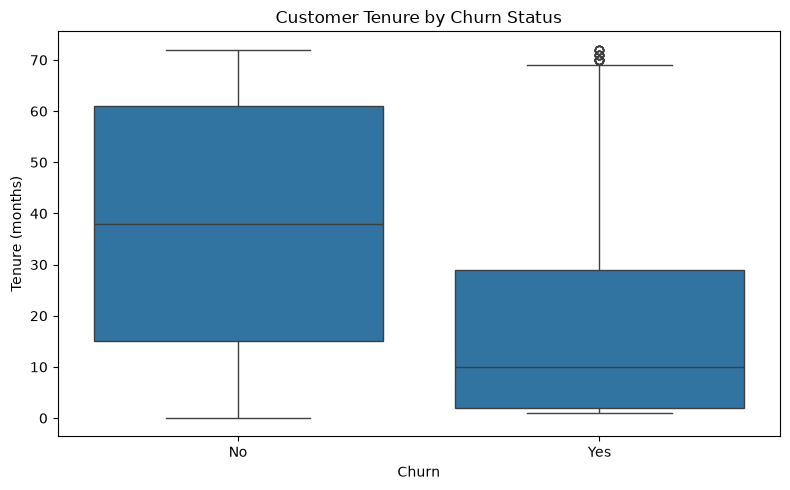

,count,mean,median,std
Churn,,,,
No,5174,37.57,38.0,24.11
Yes,1869,17.98,10.0,19.53


In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.tight_layout()
plt.show()

display(
    eda.groupby("Churn")["tenure"]
       .agg(["count", "mean", "median", "std"])
       .round(2)
)

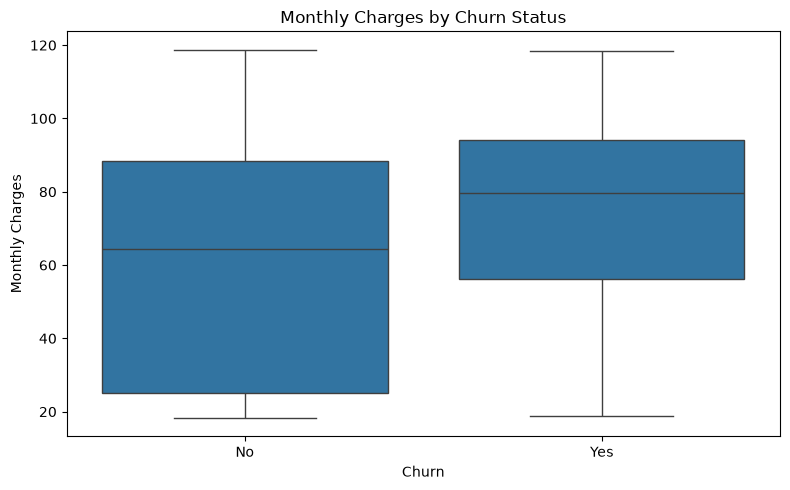

,mean,median,std
Churn,,,
No,61.27,64.43,31.09
Yes,74.44,79.65,24.67


In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

display(
    eda.groupby("Churn")["MonthlyCharges"]
       .agg(["mean", "median", "std"])
       .round(2)
)

### Comparing churn across several categories

In [20]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling",
    "OnlineSecurity",
    "TechSupport"
]

for col in categorical_features:
    if col not in eda.columns:
        continue

    rate = (
        eda.groupby(col, dropna=False)["ChurnFlag"]
           .mean()
           .mul(100)
           .sort_values(ascending=False)
    )

    print(f"\nChurn rate by {col} (%):")
    display(rate.round(2).to_frame("churn_rate"))


Churn rate by Contract (%):


,churn_rate
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83



Churn rate by InternetService (%):


,churn_rate
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40



Churn rate by PaymentMethod (%):


...

,churn_rate
PaperlessBilling,
Yes,33.57
No,16.33



Churn rate by OnlineSecurity (%):


,churn_rate
OnlineSecurity,
No,41.77
Yes,14.61
No internet service,7.40



Churn rate by TechSupport (%):


,churn_rate
TechSupport,
No,41.64
Yes,15.17
No internet service,7.40


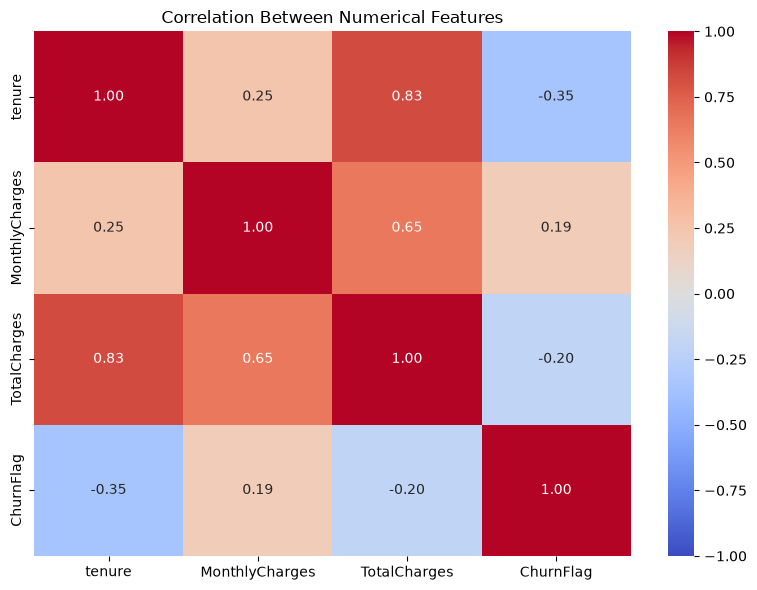

In [21]:
correlation_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "ChurnFlag"
]

corr = eda[correlation_cols].corr(method="pearson")

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Install statsmodels if needed:
# %pip install statsmodels

vif_data = eda[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].dropna()

X_vif = add_constant(vif_data)

vif_results = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

display(vif_results)

,feature,VIF
0,const,14.973839
1,tenure,5.844646
2,MonthlyCharges,3.225293
3,TotalCharges,9.526697


#### Statistical hypothesis testing

In [23]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    eda["Contract"],
    eda["Churn"]
)

display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.8f}")

alpha = 0.05

if p_value < alpha:
    print("Reject H0: evidence of an association between contract type and churn.")
else:
    print("Fail to reject H0: insufficient evidence of an association.")

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Chi-square statistic: 1184.597
Degrees of freedom: 2
P-value: 0.00000000
Reject H0: evidence of an association between contract type and churn.


In [24]:
from scipy.stats import mannwhitneyu

tenure_stayed = eda.loc[
    eda["ChurnFlag"] == 0, "tenure"
].dropna()

tenure_churned = eda.loc[
    eda["ChurnFlag"] == 1, "tenure"
].dropna()

statistic, p_value = mannwhitneyu(
    tenure_stayed,
    tenure_churned,
    alternative="two-sided"
)

print(f"Mann-Whitney U statistic: {statistic:.2f}")
print(f"P-value: {p_value:.8f}")

print("\nMedian tenure — stayed:", tenure_stayed.median())
print("Median tenure — churned:", tenure_churned.median())

Mann-Whitney U statistic: 7154668.00
P-value: 0.00000000

Median tenure — stayed: 38.0
Median tenure — churned: 10.0


In [25]:
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.proportion import proportion_confint

month_to_month = eda["Contract"].eq("Month-to-month")
longer_contract = eda["Contract"].isin(
    ["One year", "Two year"]
)

group1 = eda.loc[month_to_month, "ChurnFlag"]
group2 = eda.loc[longer_contract, "ChurnFlag"]

successes = np.array([group1.sum(), group2.sum()])
sample_sizes = np.array([len(group1), len(group2)])

z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=sample_sizes
)

rate1 = group1.mean()
rate2 = group2.mean()
difference = rate1 - rate2

ci1 = proportion_confint(
    group1.sum(), len(group1), method="wilson"
)
ci2 = proportion_confint(
    group2.sum(), len(group2), method="wilson"
)

print(f"Month-to-month churn rate: {rate1:.2%}")
print(f"Longer-contract churn rate: {rate2:.2%}")
print(f"Absolute difference: {difference:.2%}")
print(f"Z statistic: {z_stat:.3f}")
print(f"P-value: {p_value:.8f}")
print(f"Month-to-month 95% CI: ({ci1[0]:.2%}, {ci1[1]:.2%})")
print(f"Longer-contract 95% CI: ({ci2[0]:.2%}, {ci2[1]:.2%})")

Month-to-month churn rate: 42.71%
Longer-contract churn rate: 6.76%
Absolute difference: 35.95%
Z statistic: 33.997
P-value: 0.00000000
Month-to-month 95% CI: (41.16%, 44.27%)
Longer-contract 95% CI: (5.93%, 7.68%)


##### Business KPIs and actionable insights

In [26]:
total_customers = len(eda)
churned_customers = int(eda["ChurnFlag"].sum())
retained_customers = total_customers - churned_customers

churn_rate = churned_customers / total_customers

average_monthly_charge = eda["MonthlyCharges"].mean()

# Descriptive revenue exposure: current monthly charges
# associated with customers who have churned.
churned_monthly_charge = eda.loc[
    eda["ChurnFlag"] == 1, "MonthlyCharges"
].sum()

kpis = pd.DataFrame({
    "Metric": [
        "Total customers",
        "Churned customers",
        "Retained customers",
        "Churn rate (%)",
        "Average monthly charges",
        "Monthly charges of churned customers"
    ],
    "Value": [
        total_customers,
        churned_customers,
        retained_customers,
        round(churn_rate * 100, 2),
        round(average_monthly_charge, 2),
        round(churned_monthly_charge, 2)
    ]
})

display(kpis)

,Metric,Value
0,Total customers,7043.00
1,Churned customers,1869.00
2,Retained customers,5174.00
3,Churn rate (%),26.54
4,Average monthly charges,64.76
5,Monthly charges of churned customers,139130.85


In [27]:
segment_cols = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

segment_results = []

for col in segment_cols:
    segment = (
        eda.groupby(col, dropna=False)
           .agg(
               customers=("ChurnFlag", "size"),
               churn_rate=("ChurnFlag", "mean"),
               avg_monthly_charges=("MonthlyCharges", "mean")
           )
           .reset_index()
           .rename(columns={col: "segment"})
    )

    segment["feature"] = col
    segment["churn_rate_pct"] = segment["churn_rate"] * 100

    segment_results.append(segment)

segment_summary = pd.concat(
    segment_results,
    ignore_index=True
)

display(
    segment_summary.sort_values(
        ["churn_rate", "customers"],
        ascending=[False, False]
    ).head(15).round(3)
)

,segment,customers,churn_rate,avg_monthly_charges,feature,churn_rate_pct
8,Electronic check,2365,0.453,76.256,PaymentMethod,45.285
0,Month-to-month,3875,0.427,66.398,Contract,42.710
4,Fiber optic,3096,0.419,91.500,InternetService,41.893
13,No,3498,0.418,75.693,OnlineSecurity,41.767
10,No,3473,0.416,74.587,TechSupport,41.635
9,Mailed check,1612,0.191,43.917,PaymentMethod,19.107
3,DSL,2421,0.190,58.102,InternetService,18.959
6,Bank transfer (automatic),1544,0.167,67.193,PaymentMethod,16.710
7,Credit card (automatic),1522,0.152,66.512,PaymentMethod,15.243
12,Yes,2044,0.152,80.680,TechSupport,15.166


In [28]:
from statsmodels.stats.proportion import proportion_confint

successes = int(eda["ChurnFlag"].sum())
n = len(eda)

lower, upper = proportion_confint(
    count=successes,
    nobs=n,
    alpha=0.05,
    method="wilson"
)

print(f"Observed churn rate: {successes / n:.2%}")
print(f"95% Wilson confidence interval: {lower:.2%} to {upper:.2%}")

Observed churn rate: 26.54%
95% Wilson confidence interval: 25.52% to 27.58%


#### Creating the EDA Report

In [34]:
eda_report = {
    "dataset_rows": len(eda),
    "dataset_columns": eda.shape[1],
    "duplicate_rows": int(eda.duplicated().sum()),
    "missing_cells": int(eda.isna().sum().sum()),
    "churned_customers": int(eda["ChurnFlag"].sum()),
    "retained_customers": int((eda["ChurnFlag"] == 0).sum()),
    "churn_rate_pct": round(eda["ChurnFlag"].mean() * 100, 2),
    "avg_tenure_months": round(eda["tenure"].mean(), 2),
    "avg_monthly_charges": round(eda["MonthlyCharges"].mean(), 2)
}

for metric, value in eda_report.items():
    print(f"{metric}: {value}")

# Save the results for the next project stages.
Path("reports").mkdir(exist_ok=True)

pd.DataFrame(
    list(eda_report.items()),
    columns=["metric", "value"]
).to_csv("reports/eda_summary.csv", index=False)

segment_summary.to_csv(
    "reports/customer_segment_analysis.csv",
    index=False
)

print("\nEDA reports saved successfully.")

dataset_rows: 7043
dataset_columns: 22
duplicate_rows: 0
missing_cells: 11
churned_customers: 1869
retained_customers: 5174
churn_rate_pct: 26.54
avg_tenure_months: 32.37
avg_monthly_charges: 64.76

EDA reports saved successfully.
